In [31]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [32]:
df = pd.read_csv('tested_titanic.csv')

In [33]:
df['Family'] = df['SibSp'] + df['Parch'] + 1

df = df[['Age', 'Fare', 'Family', 'Survived']]
df.head()

,Age,Fare,Family,Survived
0,34.5,7.8292,1,0
1,47.0,7.0000,2,1
2,62.0,9.6875,1,0
3,27.0,8.6625,1,0
4,22.0,12.2875,3,1


In [34]:
df.to_csv('toyset_titanic.csv', index=False)

In [35]:
df.info


<bound method DataFrame.info of       Age      Fare  Family  Survived
0    34.5    7.8292       1         0
1    47.0    7.0000       2         1
2    62.0    9.6875       1         0
3    27.0    8.6625       1         0
4    22.0   12.2875       3         1
..    ...       ...     ...       ...
413   NaN    8.0500       1         0
414  39.0  108.9000       1         1
415  38.5    7.2500       1         0
416   NaN    8.0500       1         0
417   NaN   22.3583       3         0

[418 rows x 4 columns]>

In [36]:
df['Fare'].isnull()

0      False
1      False
2      False
3      False
4      False
       ...  
413    False
414    False
415    False
416    False
417    False
Name: Fare, Length: 418, dtype: bool

In [37]:
df.loc[[0, 2, 4], 'Fare'] = np.nan

# Check missing values again
df.isnull().sum()

Age         86
Fare         4
Family       0
Survived     0
dtype: int64

In [38]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2
)
X_train.shape, X_test.shape

((334, 3), (84, 3))

In [40]:
# Calculate mean and median from the training set
mean_age = X_train['Age'].mean()
median_age = X_train['Age'].median()

mean_fare = X_train['Fare'].mean()
median_fare = X_train['Fare'].median()

# Fill missing values in training and testing sets
X_train['Age_median'] = X_train['Age'].fillna(median_age)
X_train['Age_mean'] = X_train['Age'].fillna(mean_age)

X_train['Fare_median'] = X_train['Fare'].fillna(median_fare)
X_train['Fare_mean'] = X_train['Fare'].fillna(mean_fare)

In [41]:
X_train.sample(5)

,Age,Fare,Family,Age_median,Age_mean,Fare_median,Fare_mean
371,31.0,134.5000,1,31.0,31.000000,134.5000,134.5000
66,18.0,7.8792,1,18.0,18.000000,7.8792,7.8792
72,29.0,7.9250,1,29.0,29.000000,7.9250,7.9250
158,42.0,26.5500,1,42.0,42.000000,26.5500,26.5500
127,NaN,23.2500,3,27.0,29.307252,23.2500,23.2500


In [42]:
# Check variance for Age and Fare before and after imputation
print('Original Age variable variance: ', X_train['Age'].var())
print(
    'Age Variance after median imputation: ',
    X_train['Age_median'].var(),
)
print('Age Variance after mean imputation: ', X_train['Age_mean'].var())

print('Original Fare variable variance: ', X_train['Fare'].var())
print(
    'Fare Variance after median imputation: ',
    X_train['Fare_median'].var(),
)
print('Fare Variance after mean imputation: ', X_train['Fare_mean'].var())

Original Age variable variance:  184.7040299669505
Age Variance after median imputation:  145.67090989552415
Age Variance after mean imputation:  144.76802348760975
Original Fare variable variance:  2343.7191796556795
Fare Variance after median imputation:  2325.9666436912134
Fare Variance after mean imputation:  2322.604592451574


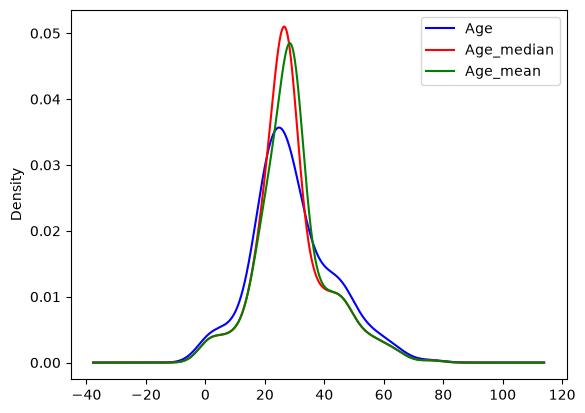

In [43]:
# Plot the distribution comparison for Age
fig = plt.figure()
ax = fig.add_subplot(111)

# Original variable distribution with missing values
X_train['Age'].plot(kind='kde', ax=ax, color='blue', label='Age')

# Variable imputed with the median
X_train['Age_median'].plot(kind='kde', ax=ax, color='red', label='Age_median')

# Variable imputed with the mean
X_train['Age_mean'].plot(kind='kde', ax=ax, color='green', label='Age_mean')

# Add legends
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [46]:
# Create a fresh X using only the original columns for the ColumnTransformer
X_trf = df[['Age', 'Fare']]
y_trf = df['Survived']

# Split this clean data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_trf, y_trf, test_size=0.2, random_state=2
)

# Now fit and transform smoothly
trf.fit(X_train)
X_train_transformed = trf.transform(X_train)
X_test_transformed = trf.transform(X_test)

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

imputer_age = SimpleImputer(strategy='median')
imputer_fare = SimpleImputer(strategy='mean')

trf = ColumnTransformer(
    [
        ('imputer_age', imputer_age, ['Age']),
        ('imputer_fare', imputer_fare, ['Fare']),
    ],
    remainder='passthrough',
)

In [48]:
trf.fit(X_train)

X_train_transformed = trf.transform(X_train)
X_test_transformed = trf.transform(X_test)

In [49]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=['Age', 'Fare'])
X_train_transformed_df.head()

,Age,Fare
0,23.0,8.6625
1,2.0,20.2125
2,39.0,13.4167
3,21.0,7.2250
4,31.0,21.0000


In [50]:
# Filling missing values with custom arbitrary constants (e.g., 99 or -1)
X_train['Age_99'] = X_train['Age'].fillna(99)
X_train['Age_minus1'] = X_train['Age'].fillna(-1)

X_train['Fare_999'] = X_train['Fare'].fillna(999)
X_train['Fare_minus1'] = X_train['Fare'].fillna(-1)